In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [15]:

train_df = pd.read_csv("Linear Regression Train.csv")
test_df  = pd.read_csv("Linear Regression Test.csv")

print("Train Shape:", train_df.shape)
print("Test Shape:", test_df.shape)
print(train_df.info())

Train Shape: (600000, 16)
Test Shape: (150000, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600000 entries, 0 to 599999
Data columns (total 16 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   feat_1   600000 non-null  float64
 1   feat_2   600000 non-null  float64
 2   feat_3   600000 non-null  float64
 3   feat_4   600000 non-null  float64
 4   feat_5   600000 non-null  float64
 5   feat_6   600000 non-null  float64
 6   feat_7   600000 non-null  float64
 7   feat_8   600000 non-null  float64
 8   feat_9   600000 non-null  float64
 9   feat_10  600000 non-null  float64
 10  feat_11  600000 non-null  float64
 11  feat_12  600000 non-null  float64
 12  feat_13  600000 non-null  float64
 13  feat_14  600000 non-null  float64
 14  feat_15  600000 non-null  float64
 15  target   600000 non-null  float64
dtypes: float64(16)
memory usage: 73.2 MB
None


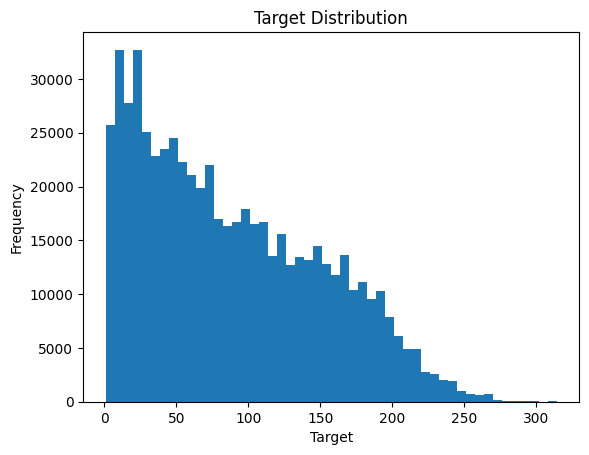

In [16]:
train_df.fillna(train_df.mean(), inplace=True)
test_df.fillna(test_df.mean(), inplace=True)

plt.figure()
plt.hist(train_df["target"], bins=50)
plt.title("Target Distribution")
plt.xlabel("Target")
plt.ylabel("Frequency")
plt.show()


In [17]:
X = train_df.drop(columns=["target"]).values
y = train_df["target"].values.reshape(-1, 1)
X_test = test_df.values

np.random.seed(42)
indices = np.random.permutation(len(X))
split = int(0.8 * len(X))

train_idx = indices[:split]
val_idx   = indices[split:]

X_train, X_val = X[train_idx], X[val_idx]
y_train, y_val = y[train_idx], y[val_idx]


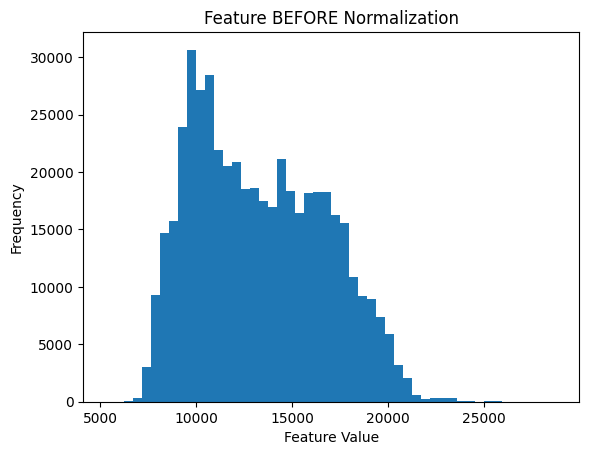

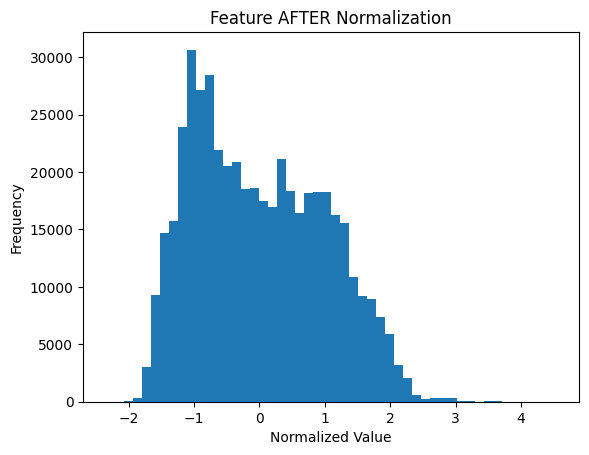

In [18]:
feature_idx =  7

plt.figure()
plt.hist(X_train[:, feature_idx], bins=50)
plt.title("Feature BEFORE Normalization")
plt.xlabel("Feature Value")
plt.ylabel("Frequency")
plt.show()

feature_idx
mean = X_train.mean(axis=0)
std  = X_train.std(axis=0)


X_train = (X_train - mean) / std
X_val   = (X_val   - mean) / std
X_test  = (X_test  - mean) / std


plt.figure()
plt.hist(X_train[:, feature_idx], bins=50)
plt.title("Feature AFTER Normalization")
plt.xlabel("Normalized Value")
plt.ylabel("Frequency")
plt.show()

In [19]:
alphas = [0.0001, 0.001, 0.005, 0.01, 0.05 ]
epochs = 3000
n_samples, n_features = X_train.shape

alpha_results = {}

for alpha in alphas:
    W = np.zeros((n_features, 1))
    b = 0.0
    losses = []

    for epoch in range(epochs):
        y_pred = X_train @ W + b
        error = y_pred - y_train

        dW = (2 / n_samples) * (X_train.T @ error)
        db = (2 / n_samples) * np.sum(error)

        W -= alpha * dW
        b -= alpha * db

        loss = np.mean(error ** 2)
        losses.append(loss)

    # validation MSE
    y_val_pred = X_val @ W + b
    val_mse = np.mean((y_val - y_val_pred) ** 2)

    alpha_results[alpha] = {
        "losses": losses,
        "val_mse": val_mse,
        "W": W,
        "b": b
    }

    print(f"Alpha {alpha} | Validation MSE: {val_mse:.4f}")


Alpha 0.0001 | Validation MSE: 2835.9093
Alpha 0.001 | Validation MSE: 260.1433
Alpha 0.005 | Validation MSE: 162.8300
Alpha 0.01 | Validation MSE: 132.0238
Alpha 0.05 | Validation MSE: 123.3134


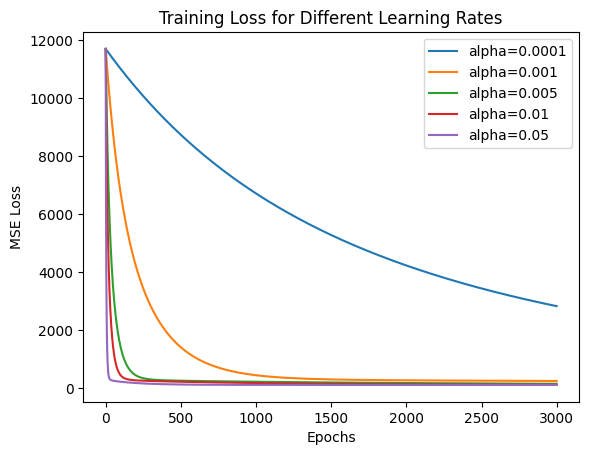


Best Alpha Selected: 0.05


In [20]:
plt.figure()
for alpha in alphas:
    plt.plot(alpha_results[alpha]["losses"], label=f"alpha={alpha}")
plt.title("Training Loss for Different Learning Rates")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()

best_alpha = min(alpha_results, key=lambda x: alpha_results[x]["val_mse"])
print("\nBest Alpha Selected:", best_alpha)


In [21]:

W = alpha_results[best_alpha]["W"]
b = alpha_results[best_alpha]["b"]

y_val_pred = X_val @ W + b
ss_res = np.sum((y_val - y_val_pred) ** 2)
ss_tot = np.sum((y_val - np.mean(y_val)) ** 2)
r2_score = 1 - (ss_res / ss_tot)

print("Validation R² Score:", r2_score)


test_predictions = X_test @ W + b

submission = pd.DataFrame({
    "target": test_predictions.flatten()
})

submission.to_csv("submission.csv", index=False)
print("Submission file saved as submission.csv")

Validation R² Score: 0.9683674862533863
Submission file saved as submission.csv
